# 02 · Baselines and statistical model

**Goal:** set the reference level that the machine learning models (LightGBM and the neural network) will have to beat. A complex model is only justified if it beats simple methods, which are also usually very competitive in retail demand.

**Models in this notebook** (all forecast 28 days from an origin, using only data prior to it):

| Model | What it does |
|---|---|
| **Zero** | Always forecasts 0. It is not a serious model: it serves to see how the metrics behave with intermittent demand. |
| **Naive** | Repeats the last observed sale. |
| **Seasonal naive** | Repeats what was sold on the same day of the previous week. |
| **28-day moving average** | Average of the last 28 days, the same for the whole horizon. |
| **Seasonal average (4 weeks)** | For each day, averages what was sold on that same day of the week over the last 4 weeks. |
| **SES + weekly index** (statistical model) | Removes the weekly seasonality, estimates the level of the series with simple exponential smoothing, and puts the seasonality back. |

**Evaluation:** according to the protocol in notebook 01, on the last two 28-day windows, with RMSSE and MAE. None of these models has hyperparameters that are tuned with the evaluation windows (the parameters were fixed in advance or are estimated only with data prior to the origin), so they can be evaluated on both windows.

## 1. Setup and data

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

from src.data import ensure_m5, load_calendar, load_sales, day_columns, sample_series, SEED
from src.metrics import rmsse, evaluar
from src.forecasting import (
    ventanas, clasificar_demanda, pronostico_cero, pronostico_ingenuo,
    pronostico_ingenuo_estacional, pronostico_media_movil,
    pronostico_promedio_estacional, ses_semanal, guardar_resultados,
)

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)

In [2]:
carpeta = ensure_m5()
calendario = load_calendar(carpeta)
ventas = load_sales(carpeta)
dias = day_columns(ventas)

muestra = sample_series(ventas, n_per_store=60, seed=SEED)
Y = muestra[dias].to_numpy().astype(float)
T = Y.shape[1]
categorias = muestra["cat_id"].astype(str).to_numpy()

# Day of the week for each calendar day (0 = Saturday, which is the first day of the data)
wday = calendario["wday"].to_numpy() - 1

H = 28
V = ventanas(T, H)
print("Sample series:", Y.shape[0], "| days:", T)
for nombre, (ini, fin) in V.items():
    print(f"{nombre:>10}: days {ini} a {fin} | origin on day {ini - 1}")

Sample series: 600 | days: 1941
validation: days 1886 a 1913 | origin on day 1885
      test: days 1914 a 1941 | origin on day 1913


### 1.1 Events within the evaluation windows

Events can alter sales, and these simple models do not use them. Those that fall within each window are listed to know how much they may affect the metrics.

In [3]:
for nombre, (ini, fin) in V.items():
    ev = calendario.iloc[ini - 1:fin]
    ev = ev[ev["event_name_1"].notna()][["date", "event_name_1", "event_type_1"]]
    print(f"{nombre} ({calendario['date'].iloc[ini - 1].date()} a {calendario['date'].iloc[fin - 1].date()}):")
    print(ev.to_string(index=False) if len(ev) else "  no events")
    print()

validation (2016-03-28 a 2016-04-24):
  no events

test (2016-04-25 a 2016-05-22):
      date   event_name_1 event_type_1
2016-04-30     Pesach End    Religious
2016-05-01 OrthodoxEaster    Religious
2016-05-05  Cinco De Mayo     Cultural
2016-05-08   Mother's day     Cultural



## 2. Forecasts

For each window, the history up to the origin is taken, the following 28 days are forecast, and they are compared with the actual sales.

**Statistical model (SES + weekly index).** Two simple steps:
1. **Weekly index:** how much more or less is sold on each day of the week relative to the average, estimated over the last year, by category and counting each series from its first sale. It is estimated with all the series in the category together, because a series with few sales would give a very noisy weekly pattern.
2. **Simple exponential smoothing:** on the series divided by the weekly index, the level is updated each day by correcting a fraction `alpha` of the error: with a high `alpha` the past is forgotten quickly and with a low `alpha` the level is more stable. Alpha is chosen per series among five values (0.02 to 0.4), the one that best predicted the last 364 days **prior to the origin**.

The forecast for each day is the final level multiplied by the index for that day of the week.

In [4]:
def contexto(origen):
    return {"wday_train": wday[:origen], "wday_futuro": wday[origen:origen + H], "grupos": categorias}

MODELOS = {
    "Zero": lambda Y_, c: pronostico_cero(Y_, H),
    "Naive": lambda Y_, c: pronostico_ingenuo(Y_, H),
    "Seasonal naive": lambda Y_, c: pronostico_ingenuo_estacional(Y_, H),
    "28-day moving average": lambda Y_, c: pronostico_media_movil(Y_, H),
    "Seasonal average (4 weeks)": lambda Y_, c: pronostico_promedio_estacional(Y_, H),
    "SES + weekly index": lambda Y_, c: ses_semanal(Y_, H, c["wday_train"], c["wday_futuro"], c["grupos"])[0],
}

entrenamiento, real, ctxs = {}, {}, {}
for nombre, (ini, fin) in V.items():
    origen = ini - 1
    entrenamiento[nombre] = Y[:, :origen]
    real[nombre] = Y[:, origen:fin]
    ctxs[nombre] = contexto(origen)

preds = {(m, v): f(entrenamiento[v], ctxs[v]) for m, f in MODELOS.items() for v in V}
print("Calculated forecasts:", len(preds))

Calculated forecasts: 12


## 3. Results

RMSSE (scaled error, simple average across series) and MAE (units per series per day). **Lower is better** for both. Series with no sales before the origin have no scale and are left out of the RMSSE; the MAE includes all series.

In [5]:
filas = [{"model": m, "window": v, **evaluar(entrenamiento[v], real[v], p)} for (m, v), p in preds.items()]
resultados = pd.DataFrame(filas)

tabla = resultados.pivot(index="model", columns="window", values=["RMSSE", "MAE"])
tabla = tabla[[("RMSSE", "validation"), ("RMSSE", "test"), ("MAE", "validation"), ("MAE", "test")]]
tabla = tabla.sort_values(("RMSSE", "validation"))
display_tabla = tabla.round(3)
print(resultados.groupby("window")[["valid_series", "total_series"]].first().to_string())
print()
display_tabla

            valid_series  total_series
window                                
test                 600           600
validation           600           600



RMSSE               MAE       
window                     validation   test validation   test
model                                                         
SES + weekly index              0.742  0.769      1.036  1.008
28-day moving average           0.751  0.782      1.020  1.059
Seasonal average (4 weeks)      0.811  0.849      1.045  1.101
Naive                           0.936  1.007      1.361  1.306
Zero                            0.940  0.990      1.392  1.477
Seasonal naive                  0.995  1.029      1.195  1.233

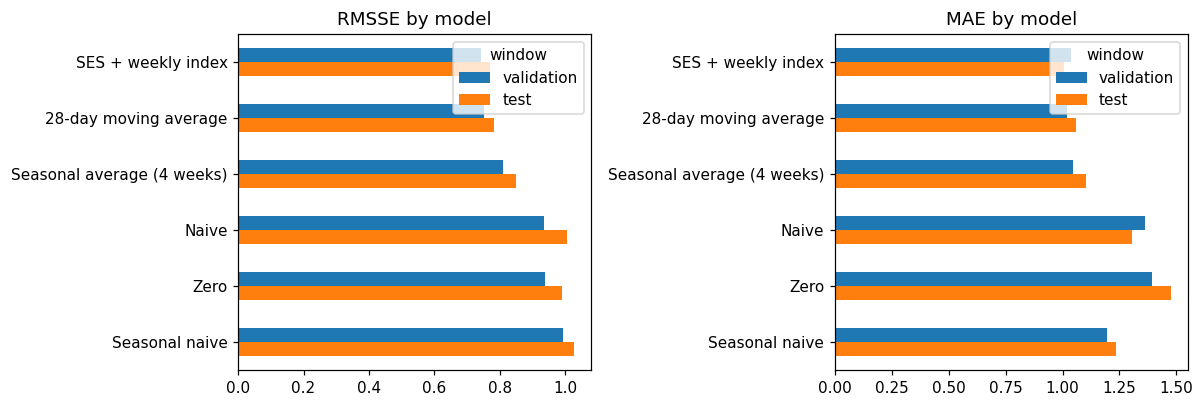

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metrica in zip(axes, ["RMSSE", "MAE"]):
    tabla[metrica].plot.barh(ax=ax)
    ax.set_title(metrica + " by model")
    ax.set_ylabel("")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 3.1 RMSSE and MAE do not always rank the same way

The MAE is minimized by forecasting the **median** of each series (which in many sporadic series is zero), while the RMSSE, based on squared errors, is minimized by forecasting the **mean**. That is why the two metrics can rank the models differently. The "Zero" model, useless for planning, is included to check this: the table compares it with two reference models.

In [7]:
r = resultados[resultados["model"].isin(["Zero", "Seasonal average (4 weeks)", "SES + weekly index"])]
r.pivot(index="model", columns="window", values=["RMSSE", "MAE"]).round(3)

RMSSE               MAE           
window                       test validation   test validation
model                                                         
SES + weekly index          0.769      0.742  1.008      1.036
Seasonal average (4 weeks)  0.849      0.811  1.101      1.045
Zero                        0.990      0.940  1.477      1.392

### 3.2 Are there fewer days with no sales in the recent period?

The "Zero" model turned out to be uncompetitive in MAE. One possible explanation is that sales grow over time and, because of that, there are fewer days with no sales in the recent period than in the history of each series. The proportion of days with no sales (counted from the first sale of each series) is compared with that of the last 56 days, and we measure what proportion of series have a median of zero over those 56 days: the MAE is minimized by forecasting the median, so "Zero" would only be optimal in series with a median of zero. This is a description of the sample and is not used to tune any model.

In [8]:
inicio = (Y > 0).argmax(axis=1)
ceros_historia = np.mean([(Y[i, inicio[i]:] == 0).mean() for i in range(len(Y))])
ceros_reciente = (Y[:, -56:] == 0).mean()
mediana_cero = (np.median(Y[:, -56:], axis=1) == 0).mean()

print(f"Proportion of days with no sales (since the first sale): {ceros_historia:.3f} | last 56 days: {ceros_reciente:.3f}")
print(f"Series with a median of zero over the last 56 days: {mediana_cero:.1%}")

Proportion of days with no sales (since the first sale): 0.615 | last 56 days: 0.556
Series with a median of zero over the last 56 days: 60.0%


## 4. Results by demand type

The series are classified (smooth, erratic, intermittent, lumpy) using **only the history prior to the origin**, so as not to leak information from the future. The results of the validation window are shown: simple averages within each type.

In [9]:
def desglose(ventana):
    tipo = clasificar_demanda(entrenamiento[ventana])["type"].to_numpy()
    filas = []
    for m in MODELOS:
        r_ = rmsse(entrenamiento[ventana], real[ventana], preds[(m, ventana)])
        a_ = np.abs(real[ventana] - preds[(m, ventana)]).mean(axis=1)
        g = pd.DataFrame({"type": tipo, "RMSSE": r_, "MAE": a_}).groupby("type").agg(
            RMSSE=("RMSSE", "mean"), MAE=("MAE", "mean"), series=("MAE", "size"))
        g["model"] = m
        filas.append(g.reset_index())
    return pd.concat(filas, ignore_index=True)

d_val = desglose("validation")
print("Series by type (validation):", d_val.groupby("type")["series"].first().to_dict())
print()
print("RMSSE by demand type:")
d_val.pivot(index="model", columns="type", values="RMSSE").round(3)

Series by type (validation): {'erratic': 19, 'intermittent': 434, 'irregular': 121, 'smooth': 26}

RMSSE by demand type:


type,erratic,intermittent,irregular,smooth
model,,,,
28-day moving average,0.912,0.765,0.688,0.689
Naive,1.235,0.943,0.871,0.912
SES + weekly index,0.877,0.756,0.686,0.668
Seasonal average (4 weeks),0.965,0.828,0.746,0.722
Seasonal naive,1.072,1.016,0.932,0.873
Zero,1.615,0.910,0.891,1.167


In [10]:
print("MAE by demand type:")
d_val.pivot(index="model", columns="type", values="MAE").round(3)

MAE by demand type:


type,erratic,intermittent,irregular,smooth
model,,,,
28-day moving average,4.011,0.726,1.363,2.142
Naive,5.778,0.953,1.790,2.946
SES + weekly index,4.031,0.742,1.383,2.133
Seasonal average (4 weeks),4.104,0.733,1.427,2.254
Seasonal naive,4.658,0.824,1.672,2.647
Zero,8.771,0.846,1.698,3.691


## 5. The statistical model under the hood

**Weekly index by category**, estimated at the test origin. A value of 1.2 means that on that day 20% more is sold than the average.

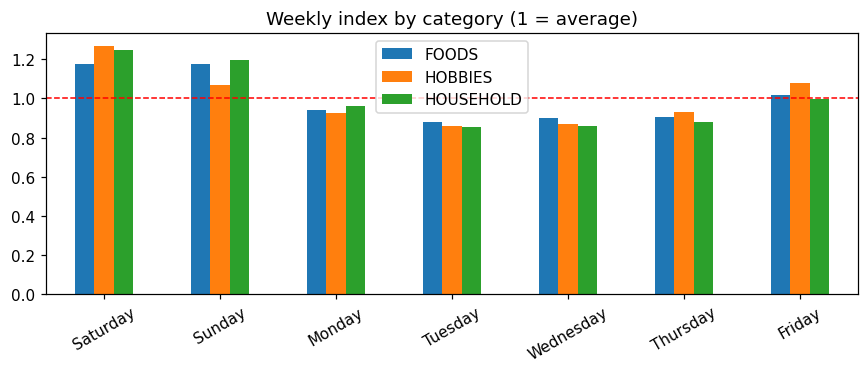

Alpha chosen per series (test origin):


,series
0.02,344
0.05,122
0.10,73
0.20,46
0.40,15


In [11]:
dias_semana = ["Saturday", "Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
_, info = ses_semanal(entrenamiento["test"], H, ctxs["test"]["wday_train"], ctxs["test"]["wday_futuro"], categorias)

indices = pd.DataFrame(info["indices"], index=dias_semana)
ax = indices.plot.bar(figsize=(8, 3.5), rot=30)
ax.axhline(1, color="red", linestyle="--", linewidth=1)
ax.set_title("Weekly index by category (1 = average)")
plt.tight_layout()
plt.show()

print("Alpha chosen per series (test origin):")
pd.Series(info["alphas"]).value_counts().sort_index().to_frame("series")

## 6. Forecast examples

A smooth series and an intermittent one from the validation window: the last 70 days of history, the actual sales over the following 28 days, and the forecasts of two models.

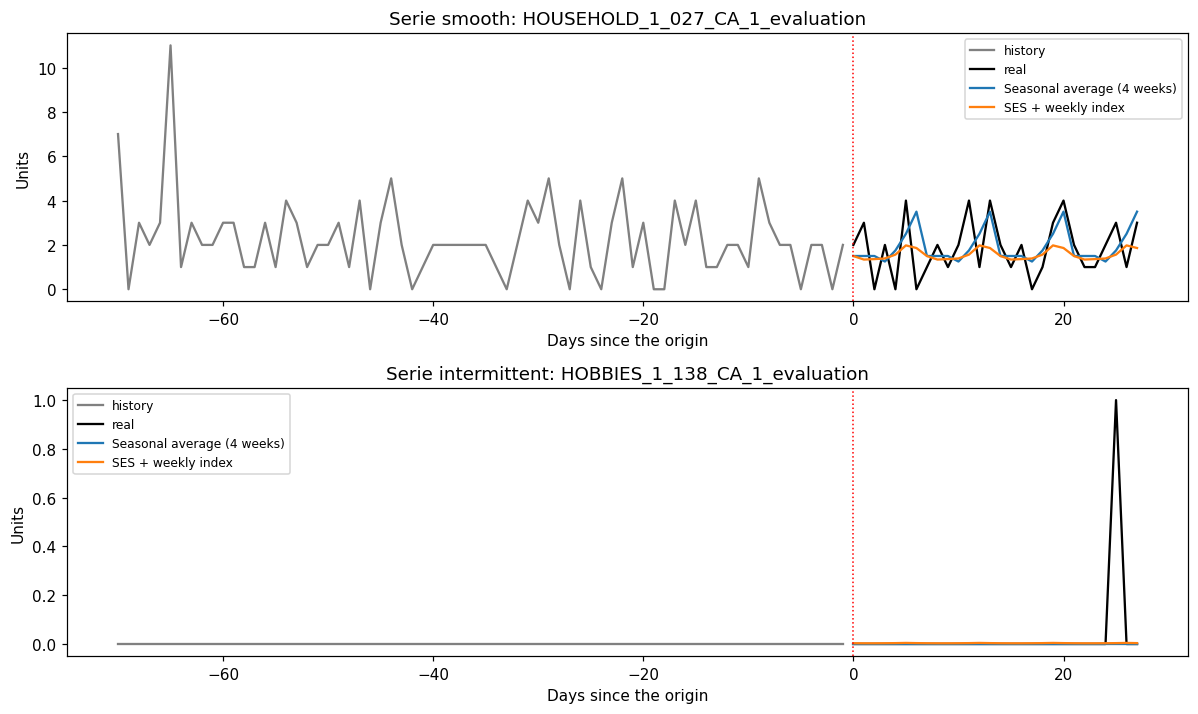

In [12]:
v = "validation"
tipo_val = clasificar_demanda(entrenamiento[v])["type"].to_numpy()
ejemplos = {t: int(np.where(tipo_val == t)[0][0]) for t in ["smooth", "intermittent"] if (tipo_val == t).any()}

fig, axes = plt.subplots(len(ejemplos), 1, figsize=(11, 3.3 * len(ejemplos)), squeeze=False)
for ax, (t, i) in zip(axes.ravel(), ejemplos.items()):
    ax.plot(np.arange(-70, 0), entrenamiento[v][i, -70:], color="gray", label="history")
    ax.plot(np.arange(0, H), real[v][i], color="black", label="real")
    for m in ["Seasonal average (4 weeks)", "SES + weekly index"]:
        ax.plot(np.arange(0, H), preds[(m, v)][i], label=m)
    ax.axvline(0, color="red", linestyle=":", linewidth=1)
    ax.set_title(f"Serie {t}: {muestra['id'].iloc[i]}")
    ax.set_xlabel("Days since the origin")
    ax.set_ylabel("Units")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Save results

In [13]:
ruta = os.path.join(ROOT, "reports", "resultados_modelos.csv")
acumulado = guardar_resultados(resultados, ruta)
print("Results saved in", ruta, "|", len(acumulado), "rows")

Results saved in c:\Users\Carlos\Desktop\Python-Prep\proyecto_forecasting_walmart\reports\resultados_modelos.csv | 12 rows


## 8. Conclusions

- **Windows:** validation (March 28 to April 24, 2016) has no events; test (April 25 to May 22) has four: Pesach End, Orthodox Easter, Cinco de Mayo, and Mother's Day. All 600 series have sales prior to both origins, so all of them are included in the RMSSE calculation.
- **Best model:** SES + weekly index has the lowest RMSSE in both windows (0.742 in validation and 0.769 in test). The 28-day moving average follows closely (0.751 and 0.782): the difference is 1 to 2% and is measured with a single window per stage, without a confidence interval, so it is not conclusive. In MAE, the moving average wins in validation (1.020 versus 1.036) and SES in test (1.008 versus 1.059).
- **Models that repeat values from specific days perform worse:** the seasonal naive (RMSSE 0.995 and 1.029) and the 4-week seasonal average (0.811 and 0.849) fall behind the moving average. With series this sporadic, what was sold on a specific day is very noisy. The weekly index shared by category in SES recovers the weekly pattern without that noise (0.742 versus 0.811 in validation).
- **An RMSSE below 1 is not a good result in itself:** even always forecasting zero gives 0.940 and 0.990. The values serve to compare models with each other, not against the threshold of 1.
- **MAE and RMSSE do not always rank the same way:** the seasonal naive beats "Zero" in MAE (1.195 versus 1.392 in validation; 1.233 versus 1.477 in test) but loses in RMSSE (0.995 versus 0.940; 1.029 versus 0.990). On the other hand, "Zero" is the worst model in MAE in both windows: forecasting zero is not competitive in this sample.
- **By demand type (validation; 19 erratic, 434 intermittent, 121 lumpy, and 26 smooth series):** SES has the lowest RMSSE in all four types (erratic 0.877, intermittent 0.756, lumpy 0.686, and smooth 0.668), although the advantage over the moving average is 0.3 to 4%. In MAE, the moving average is better in erratic, intermittent, and lumpy (4.011, 0.726, and 1.363) and SES only in smooth (2.133). The erratic and smooth series, which are few, have the highest errors in units (4.0 and 2.1 versus 0.7 in the intermittent ones), so they weigh heavily in the overall MAE.
- **The statistical model under the hood:** 344 of the 600 series (57%) choose the lowest alpha in the grid (0.02) and only 15 choose the highest (0.4). The level of most series moves very slowly and the lower end of the grid may be limiting; the grid was not widened so as not to tune the model by looking at the test window.
- **Weekly index by category:** it has the same shape in all three categories: Saturday and Sunday are the highest days, and on each day the three categories have similar values, except on Sunday, where HOBBIES is about 10% lower (value read from the chart).
- **Days with no sales over time:** the proportion of days with no sales was 0.615 over the whole history (from the first sale of each series) and 0.556 over the last 56 days, a moderate difference of about 6 points that may reflect the growth in sales or the fact that the first months of each new series are more sporadic. 60% of the series have a median of zero over those 56 days, that is, zero is the median of most series; even so, "Zero" is the worst model in MAE. Therefore, the explanation is not that most series have a non-zero median. The tables by type point to other causes: (1) the 45 erratic and smooth series (7.5% of the sample) account for about 31% of the absolute error of "Zero" in validation (calculation made from the tables by type, weighting by the number of series of each type); and (2) even among the 434 intermittent series, "Zero" has a higher MAE (0.846) than the moving average (0.726). This suggests, as an unverified hypothesis, that the sales of those series are clustered in periods, so a level that follows recent data beats a fixed value of zero.
- **Reference for the following models:** SES + weekly index, with RMSSE of 0.742 (validation) and 0.769 (test) and MAE of 1.036 and 1.008. LightGBM and the neural network will have to beat these values.
- **Limitations:** a single window per stage and no confidence intervals; 600 series chosen at random out of the 30,490; models that do not use events, SNAP, or prices; and a validation window without events and a test window with low-impact events, both without the strongest holidays.